In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn import metrics
import pickle

In [2]:
url = "https://ddc-datascience.s3.amazonaws.com/boston.csv"
boston = pd.read_csv( url, index_col = 0 )


In [3]:
boston.shape


(490, 13)

In [4]:
boston.head()


,per_cap_crime,res_zoning_prop,business_prop,river_front,nitric_oxide_conc,num_rooms,units_before_1940,distance_to_employment,distance_to_hwy,prop_tax,pupil_teacher_ratio,perc_lower_status,med_home_value
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [5]:
boston.info()


<class 'pandas.core.frame.DataFrame'>
Index: 490 entries, 0 to 505
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   per_cap_crime           490 non-null    float64
 1   res_zoning_prop         490 non-null    float64
 2   business_prop           490 non-null    float64
 3   river_front             490 non-null    float64
 4   nitric_oxide_conc       490 non-null    float64
 5   num_rooms               490 non-null    float64
 6   units_before_1940       490 non-null    float64
 7   distance_to_employment  490 non-null    float64
 8   distance_to_hwy         490 non-null    float64
 9   prop_tax                490 non-null    float64
 10  pupil_teacher_ratio     490 non-null    float64
 11  perc_lower_status       490 non-null    float64
 12  med_home_value          490 non-null    float64
dtypes: float64(13)
memory usage: 53.6 KB


## Decision Tree Regression

In [6]:
X = boston.drop('med_home_value', axis = 1)
y = boston['med_home_value']


In [7]:
# this line intentionally left blank
numLoops = 500

mean_error = np.zeros(numLoops)

np.random.seed(42)
for idx in range(0,numLoops):
  X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)
  model = DecisionTreeRegressor(max_depth=4, random_state=0)
  model.fit(X_train,y_train)
  y_pred = model.predict(X_test)
  mean_error[idx] = mean_squared_error(y_test, y_pred)

print(f'RMSE: {np.sqrt(mean_error).mean()*1000}')
print(f'RMSE_std: {np.sqrt(mean_error).std()*1000}')


RMSE: 3761.875624940422
RMSE_std: 433.9337012216631


#Random Forest

In [8]:
# two hyperparameters - n_estimators (number of trees), max_depth (number of splits)
numLoops = 500

mean_error = np.zeros(numLoops)

# np.random.seed(42)
for idx in range(0,numLoops):
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )
  model = RandomForestRegressor( n_estimators = 10 )  # n_estimators is number of trees in forest. Note: you can also choose max_depth for RFs
  model.fit( X_train, y_train )
  y_pred = model.predict( X_test )
  mean_error[idx] = mean_squared_error( y_test, y_pred )

print(f'RMSE: {np.sqrt(mean_error).mean()*1000}')
print(f'RMSE_std: {np.sqrt(mean_error).std()*1000}')
np.sqrt(mean_error)[:50]


RMSE: 3051.946289277801
RMSE_std: 374.5901956944394


array([3.27068831, 3.07867567, 3.38352597, 3.00415172, 2.62735667,
       3.78253681, 3.97466633, 3.41901167, 2.93060086, 3.30057864,
       3.10430609, 3.12713454, 2.86286819, 2.99826821, 2.66433301,
       3.024629  , 2.62540162, 2.64183281, 2.57680014, 2.55289272,
       3.27232817, 2.7135138 , 2.76129184, 3.0846564 , 2.47857184,
       3.06336783, 2.89467756, 2.84027521, 2.98699784, 2.53283035,
       2.80051599, 2.87213957, 3.35953942, 3.42771463, 2.6052028 ,
       2.95506069, 3.04087897, 3.13475872, 2.72126059, 3.20030085,
       2.80517325, 2.92328094, 3.74237715, 2.69505405, 3.77011896,
       3.1372606 , 2.71872306, 2.99992534, 3.52735809, 3.07440786])

## How do you choose number of trees?

In [10]:
num_trees = range(10,101,25)
cv_loops = 100
rmse_results = np.zeros(len(num_trees))
std_results = np.zeros(len(num_trees))

for n, trees in enumerate(num_trees):
  rmse_cv = np.zeros(cv_loops)
  np.random.seed(42)
  for i in range(cv_loops):
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20)
    rfModel = RandomForestRegressor( n_estimators=trees )
    rfModel.fit(X_train, y_train)
    y_pred_rf = rfModel.predict(X_test)
    rmse_cv[i] = np.sqrt(mean_squared_error(y_test, y_pred_rf))

  print(trees,' trees finished.')
  rmse_results[n] = rmse_cv.mean()
  std_results[n] = rmse_cv.std()


10  trees finished.
35  trees finished.
60  trees finished.
85  trees finished.


In [ ]:
# not sure why - guess it came up in dicussion
# pickle.dump(rfModel, open('rfModel.p','wb'))


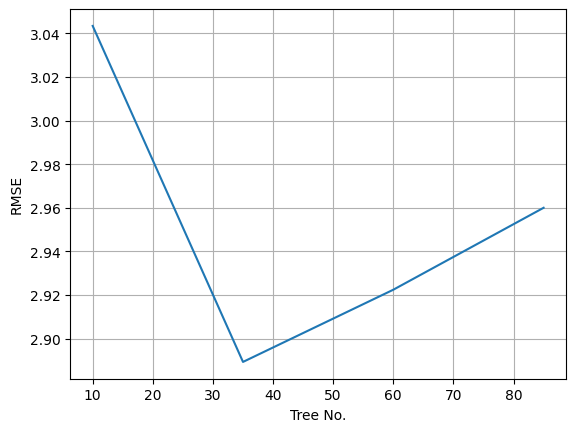

In [11]:
plt.plot(num_trees, rmse_results)
plt.xlabel('Tree No.')
plt.ylabel('RMSE')
plt.grid()


In [12]:
pd.DataFrame( zip( num_trees, rmse_results, std_results, ) , columns = "depth RMSE STDev".split() )


,depth,RMSE,STDev
0,10,3.043357,0.379701
1,35,2.889333,0.362633
2,60,2.922430,0.347761
3,85,2.959991,0.407325


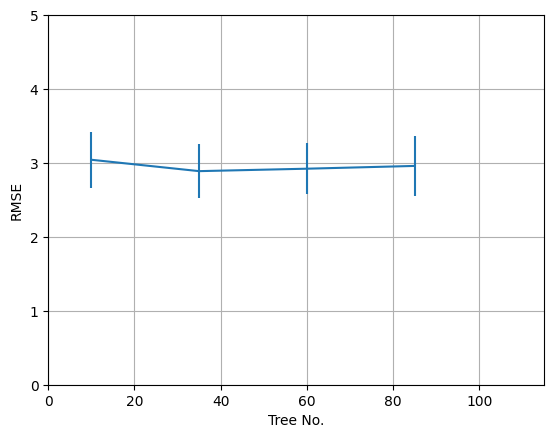

In [13]:
# plt.errorbar(num_trees, rmse_results, yerr=(std_results*2,std_results*2))
plt.errorbar(num_trees, rmse_results, yerr=std_results)
plt.xlabel('Tree No.')
plt.ylabel('RMSE')
plt.ylim(0,5)
plt.xlim(0,115)
plt.grid()


In [14]:
print(f'RMSE with 30 trees: {rmse_results[1]*1000}')


RMSE with 30 trees: 2889.3327133894295


In [15]:
import graphviz
from IPython.display import display
from sklearn import tree


In [16]:
len(rfModel.estimators_)


85

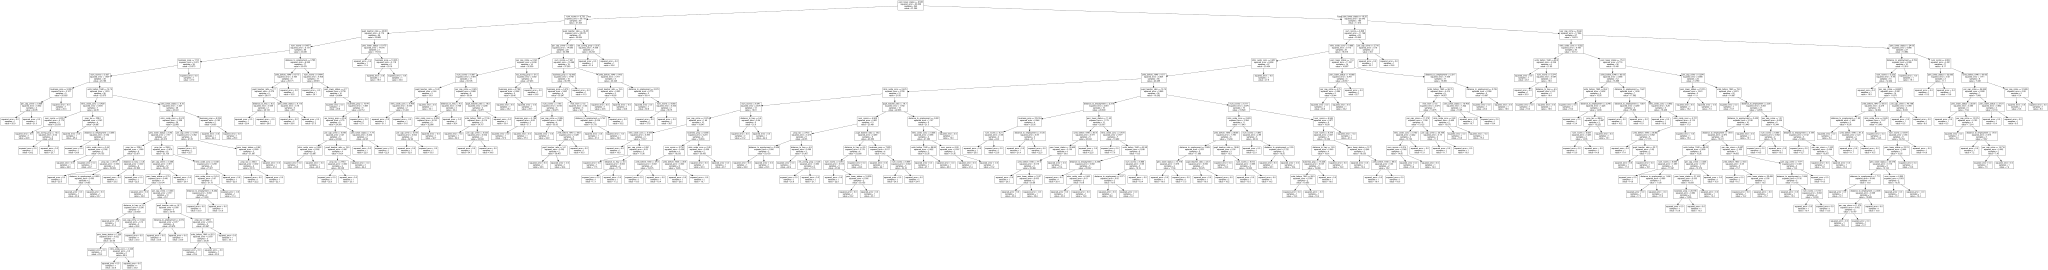

In [17]:
# Display one tree from the random forest
display(
  graphviz.Source(
    tree.export_graphviz(
      rfModel.estimators_[0],
      feature_names = X.columns,
    )
  )
)


## Find Important Predictors

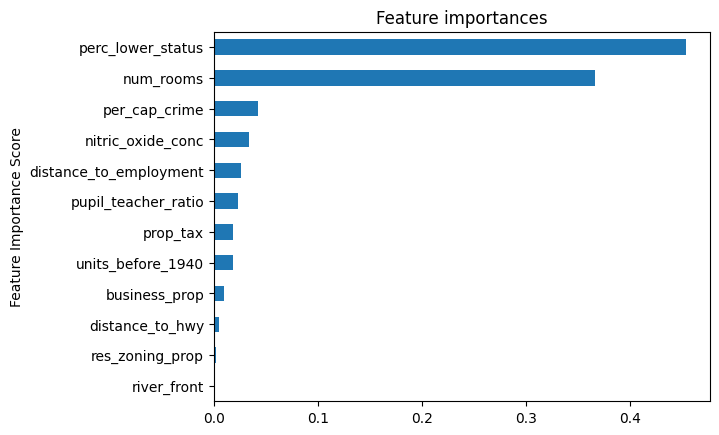

In [18]:
importances = rfModel.feature_importances_
forest_importances = pd.Series( importances, index = X.columns )

plt.figure()
# forest_importances.plot.bar()
forest_importances.sort_values( ascending = True ).plot.barh()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;


In [19]:
( forest_importances.sort_values( ascending = False ) * 100 ).cumsum()


,0
perc_lower_status,45.378385
num_rooms,82.019724
per_cap_crime,86.208697
nitric_oxide_conc,89.574982
distance_to_employment,92.222157
pupil_teacher_ratio,94.534110
prop_tax,96.393245
units_before_1940,98.195667
business_prop,99.160359
distance_to_hwy,99.624950
